# Chapitre 1 - Exercices 1.1 à 1.6

Ce notebook traite les six premiers exercices du chapitre 1, centrés sur les systèmes
opérationnels et analytiques, les données dérivées et le coût du cloud :

- **1.1** : classer des charges de travail (raisonnement et mesure sur SQLite) ;
- **1.2** : combien de requêtes analytiques une base OLTP supporte-t-elle ? (calcul
  M/M/c et simulation) ;
- **1.3** : instantanés contre flux de modifications (calcul et simulation) ;
- **1.4** : dimensionner l'écriture d'un lac sur un object store (calcul) ;
- **1.5** : graphe de dérivation, recalculs et effacement (mini-lab) ;
- **1.6** : où bascule le choix entre cloud et auto-hébergement ? (calcul analytique
  et vérification numérique).

In [1]:
import math
import sqlite3

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

from ddia import architecture as ar
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

## Exercice 1.1 : classer des charges de travail

**Énoncé.** Pour chacune des charges suivantes, dire s'il s'agit d'OLTP, d'analytique
classique (OLAP), d'analytique temps réel intégrée à un produit, ou d'un cas qui justifie
le HTAP. Justifier en une phrase (motif de lecture, motif d'écriture, utilisateur).

1. Afficher le panier d'un client sur le site marchand.
2. Le tableau de bord mensuel du chiffre d'affaires par région, consulté par la direction.
3. Vérifier, au moment d'un paiement, que la carte n'a pas dépassé son plafond quotidien,
   en agrégeant les paiements des dernières 24 heures, puis enregistrer le paiement.
4. Afficher à chaque vendeur d'une place de marché, sur sa page, le nombre de vues de ses
   annonces dans la dernière heure.
5. Un data scientist explore deux ans de clics pour trouver des variables prédictives
   de la résiliation.
6. Mettre à jour l'adresse de livraison d'un client.

Puis, **mesurer** : sur la base de ventes du cours 1, implémenter une requête pour les
charges 1, 2 et 3 et comparer la part de la table examinée par chacune.

**Rappels.** OLTP : requêtes ponctuelles par clé, écritures individuelles, utilisateur
final. OLAP : agrégats sur beaucoup de lignes, requêtes ad hoc, analyste interne.
Analytique temps réel : agrégats à faible latence, ingestion continue, intégrés au produit.
HTAP : une même application a besoin des deux (cours 1, section 3 et cours 2, section 3 ;
sections *Characterizing Transaction Processing and Analytics* et *Data Warehousing*).

**Solution.**

| charge | catégorie | justification |
|---|---|---|
| 1. panier | OLTP | lecture ponctuelle par identifiant client, utilisateur final, faible latence |
| 2. tableau de bord mensuel | OLAP | agrégat sur un mois de ventes, analyste interne, quelques requêtes par jour |
| 3. plafond de carte | HTAP | agrégat (sur les paiements récents de la carte) **et** écriture transactionnelle, dans la même requête utilisateur ; cas typique de la détection de fraude cité par le livre |
| 4. vues par vendeur | analytique temps réel | agrégat sur beaucoup d'événements, mais affiché dans le produit, frais à la minute |
| 5. exploration des clics | OLAP (lac de données) | parcours de deux ans d'historique, ad hoc, souvent hors SQL |
| 6. adresse | OLTP | écriture d'un enregistrement par clé |

Le cas 3 mérite une précision : si l'on dispose d'un index par carte et par date,
l'agrégat ne porte que sur quelques dizaines de lignes et reste une requête OLTP
raisonnable. Il devient un problème « hybride » quand les règles de fraude demandent des
agrégats plus larges (tous les paiements d'un commerçant, d'un pays, d'un type de carte).
Les catégories décrivent des **motifs d'accès**, pas des tables ou des produits.

**Vérification** : on implémente les charges 1 à 3 sur la base du cours 1 (en
interprétant le « panier » comme les achats du jour d'un client, et le « plafond » comme
la somme des achats du client sur les deux derniers jours), et on rapporte le travail au
travail d'un parcours complet de la table.

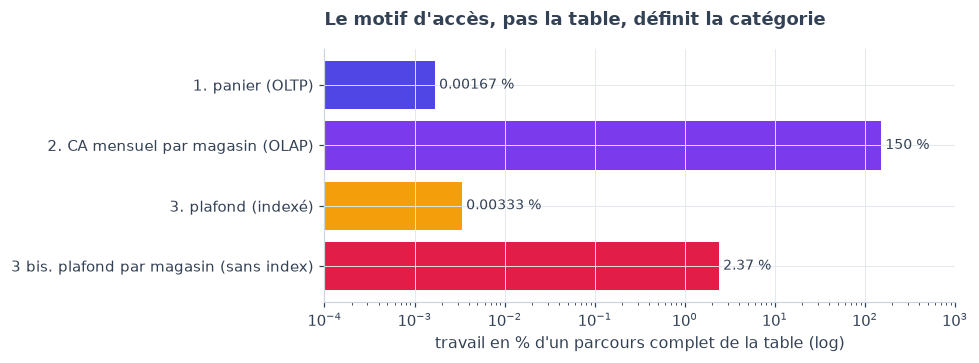

,instructions VM,part d'un parcours complet
1. panier (OLTP),10.0,1.667e-05
2. CA mensuel par magasin (OLAP),898710.0,1.498e+00
3. plafond (indexé),20.0,3.333e-05
3 bis. plafond par magasin (sans index),14210.0,2.370e-02


In [2]:
con = sqlite3.connect(":memory:")
ar.make_shop_db(con, n_sales=150_000, seed=0)
con.execute("CREATE INDEX sales_by_customer_day ON sales (customer_id, day)")
full_scan = ar.vm_steps(con, "SELECT SUM(amount) FROM sales")
Q = {"1. panier (OLTP)": ("SELECT * FROM sales WHERE customer_id = ? AND day = ?", (42, 80)),
     "2. CA mensuel par magasin (OLAP)": ("SELECT store_id, SUM(amount) FROM sales WHERE day BETWEEN 30 AND 59 GROUP BY store_id", ()),
     "3. plafond (indexé)": ("SELECT SUM(amount) FROM sales WHERE customer_id = ? AND day >= ?", (42, 88)),
     "3 bis. plafond par magasin (sans index)": ("SELECT SUM(amount) FROM sales WHERE store_id = ? AND day >= ?", (3, 88))}
res = pd.DataFrame({k: {"instructions VM": ar.vm_steps(con, sql, p),
                        "part d'un parcours complet": ar.vm_steps(con, sql, p) / full_scan} for k, (sql, p) in Q.items()}).T
fig, ax = plt.subplots(figsize=(9, 3.4))
b = ax.barh(res.index[::-1], res["part d'un parcours complet"][::-1] * 100, color=[ROSE, AMBER, VIOLET, INDIGO])
ax.set_xscale("log"); ax.bar_label(b, labels=[f"{v * 100:.3g} %" for v in res["part d'un parcours complet"][::-1]], padding=3, fontsize=9)
ax.set_xlim(1e-4, 1e3)
ax.set_xlabel("travail en % d'un parcours complet de la table (log)")
ax.set_title("Le motif d'accès, pas la table, définit la catégorie")
plt.tight_layout(); plt.show()
res

Le panier et le plafond indexé ne touchent qu'une fraction infime de la table (OLTP) ;
l'agrégat mensuel coûte même plus qu'un parcours complet (il passe par l'index des jours,
puis lit chaque ligne d'un tiers de la table) : c'est de l'OLAP. Le même contrôle de
plafond, formulé sur un critère non indexé (le magasin), fait des centaines de fois plus
de travail que la version indexée : il examine toutes les ventes des deux derniers jours,
tous clients confondus, et son coût croît avec le volume quotidien. C'est exactement ce
qui rend les règles de fraude larges difficiles à servir sur une base OLTP.

> **À retenir.** On classe une charge par son motif d'accès (combien de lignes lues, par
> quelle clé, combien de requêtes, pour qui), pas par la table qu'elle touche. Une même
> question métier peut être OLTP ou analytique selon l'index qui la sert.